# 23 Vergleichsgruppen und Nachbarn im Leitungsnetz

- Zwei Ergänzungen zum Netzvergleich aus Notebook 20.
- A: Station nur mit Häusern vergleichen, die im selben Winter ähnlich viel Wärme abgenommen haben. Fallen dann andere Stationen auf?
- B: Haben Nachbarn einer auffälligen Station im Leitungsnetz ähnliche Probleme? Das wäre ein Hinweis auf etwas Netzseitiges, etwa zu niedrigen Vorlauf oder Differenzdruck im Strang.
- Reine Analyse, das Stationsblatt bleibt unverändert. Logik in `src/vergleichsgruppen.py` und `src/nachbarschaft.py`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import alarmbewertung as ab
from src import befundcodes as bc
from src import build_graph as bg
from src import fallsammlung as fs
from src import nachbarschaft as ns
from src import netzvergleich as nv
from src import stationsblatt as bl
from src import vergleichsgruppen as vg

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

t0 = time.time()
e = bl.eingaben(ROOT)
erg = bl.rechne(e["serien"], e["termine"], e["anschlusswerte"], e["bhkw"],
                e["ohne_datum"], baujahr=e["baujahr"])
netz = erg["markiert"]
kz = erg["kennzahlen"]
kodiert = bc.kodiere_begehungen()
kat = {"mechanisch": list(fs.MECHANISCH), "ventil": ["ventil_stellantrieb"]}
print(f"{len(e['serien'])} Stundenreihen aus NB 00, gerechnet in "
      f"{time.time() - t0:.0f} s")
print("Kennzahlen im Score:", ", ".join(kz))

100 Stundenreihen aus NB 00, gerechnet in 75 s
Kennzahlen im Score: spreizung_ref_k, steigung, residuum_sd, rl_ueber_50_anteil, flow_spez_lh_kw


## A Vergleichsgruppe nach Wärmemenge

- Wärmemenge im Kernwinter: mittlere Leistung der Betriebsstunden mal Stunden des Kernwinters, damit Lücken nicht als geringer Verbrauch zählen.
- Ein Größenmaß zum Gruppieren, keine Wärmebilanz.

In [2]:
energie = vg.winterenergie(erg["punkte"])
display((energie.groupby("winter")["waermemenge_kwh"]
         .describe()[["count", "min", "50%", "max"]] / [1, 1e3, 1e3, 1e3])
        .rename(columns={"count": "stationen", "min": "min MWh",
                         "50%": "median MWh", "max": "max MWh"}).round(1))

,stationen,min MWh,median MWh,max MWh
winter,,,,
22/23,41.0,3.2,8.5,372.3
23/24,85.0,3.3,9.9,373.3
24/25,85.0,3.2,10.7,596.1
25/26,4.0,3.8,7.7,13.9


- Die Stationen unterscheiden sich um zwei Größenordnungen, die meisten liegen bei 7 bis 14 MWh je Kernwinter.
- Hängt der Netzscore am Verbrauch? Dann wäre der Vergleich mit allen unfair.

,winter,stationen,rho,p
0,22/23,41,0.323,0.039
1,23/24,85,0.141,0.197
2,24/25,85,0.155,0.156


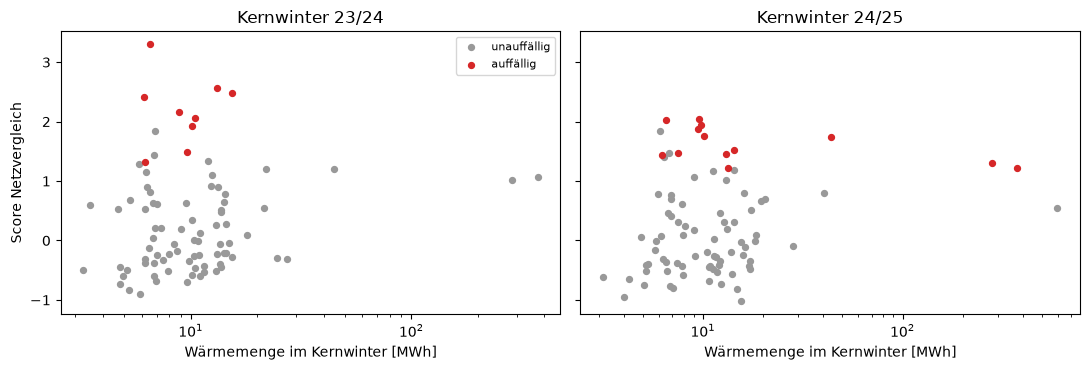

In [3]:
m = netz.merge(energie, on=["meter", "winter"])
m = m[m["score"].notna()]
zeilen = []
for w, g in m.groupby("winter"):
    if len(g) < nv.MIN_STATIONEN_WINTER:
        continue
    rho, p = stats.spearmanr(g["score"], g["waermemenge_kwh"])
    zeilen.append({"winter": w, "stationen": len(g), "rho": rho, "p": p})
display(pd.DataFrame(zeilen).round(3))

winter = [w for w in ("23/24", "24/25") if w in set(m["winter"])]
fig, ax = plt.subplots(1, len(winter), figsize=(11, 3.8), sharey=True)
for a, w in zip(np.atleast_1d(ax), winter):
    g = m[m["winter"] == w]
    for flag, farbe, name in ((False, "0.6", "unauffällig"),
                              (True, "C3", "auffällig")):
        t = g[g["auffaellig"] == flag]
        a.scatter(t["waermemenge_kwh"] / 1e3, t["score"], s=18, c=farbe,
                  label=name)
    a.set_xscale("log")
    a.set_title(f"Kernwinter {w}")
    a.set_xlabel("Wärmemenge im Kernwinter [MWh]")
np.atleast_1d(ax)[0].set_ylabel("Score Netzvergleich")
np.atleast_1d(ax)[0].legend(fontsize=8)
fig.tight_layout()

- Schwach positiv, größere Stationen schneiden eher etwas schlechter ab; signifikant nur im kleinen Winter 22/23. Die Kennzahlen sind auf die Leistung bezogen und damit schon größenunabhängig gebaut.
- Vergleichsgruppe: je Station die k Stationen mit der ähnlichsten Wärmemenge im selben Winter (ohne BHKW), z-Werte gegen diese Gruppe statt gegen das Netz. Auffällig wie gehabt, geprüft für k = 10, 15 und 25.

In [4]:
gruppen = {}
for k in vg.K_SENSITIVITAET:
    gruppen[k] = nv.markiere(vg.gruppenbezug(erg["tabelle"], energie, k=k,
                                             kennzahlen=kz), kz)
    g = gruppen[k]
    print(f"k = {k}: Bezug {g['bezug'].value_counts().to_dict()}, "
          f"Gruppe spannt im Median Faktor "
          f"{g.loc[g['bezug'] == 'gruppe', 'gruppe_faktor'].median():.2f} "
          f"in der Wärmemenge")
vergleich = pd.concat([vg.vergleiche(netz, g).assign(k=k)
                       for k, g in gruppen.items()], ignore_index=True)
vergleich = vergleich[vergleich["n"] > 0]
display(vergleich[["k", "winter", "n", "auffaellig_netz", "auffaellig_gruppe",
                   "beide", "jaccard", "spearman", "neu", "weg"]].round(2))

k = 10: Bezug {'gruppe': 211, 'zu_klein': 4}, Gruppe spannt im Median Faktor 1.19 in der Wärmemenge
k = 15: Bezug {'gruppe': 211, 'zu_klein': 4}, Gruppe spannt im Median Faktor 1.31 in der Wärmemenge
k = 25: Bezug {'gruppe': 211, 'zu_klein': 4}, Gruppe spannt im Median Faktor 1.58 in der Wärmemenge


,k,winter,n,auffaellig_netz,auffaellig_gruppe,beide,jaccard,spearman,neu,weg
0,10,22/23,41,6,7,5,0.62,0.89,"[69527345, 72135440]",[68956339]
1,10,23/24,85,9,10,7,0.58,0.90,"[66761022, 68956371, 80912202]","[68956360, 68956372]"
2,10,24/25,85,13,12,8,0.47,0.93,"[68956344, 72135440, 72167777, 80912184]","[41566330, 68956360, 68956373, 72135442, 72167..."
4,15,22/23,41,6,6,4,0.50,0.94,"[68956355, 72135440]","[68956339, 72135453]"
5,15,23/24,85,9,9,6,0.50,0.92,"[66761022, 72135440, 80912202]","[68956360, 68956372, 72167793]"
6,15,24/25,85,13,11,6,0.33,0.94,"[68956344, 72135440, 80912184, 80912199, 80912...","[41566330, 68956359, 68956360, 68956373, 72167..."
8,25,22/23,41,6,6,4,0.50,0.98,"[68956344, 68956367]","[68956339, 72135453]"
9,25,23/24,85,9,10,8,0.73,0.97,"[41566330, 80912202]",[68956360]
10,25,24/25,85,13,12,10,0.67,0.98,"[68956344, 72135440]","[41566330, 68956360, 68956373]"


- Die Rangfolge bleibt fast gleich (Rangkorrelation in allen Wintern über 0,9), die Zahl der auffälligen Stationen auch.
- Es wechseln Grenzfälle: Bei k = 15 je Winter zwei bis fünf neu und zwei bis sieben weg (Jaccard 0,33 bis 0,5), bei k = 25 nur ein bis drei Wechsel. Die Gruppen sind eng (bei k = 15 im Median Faktor 1,3 zwischen größter und kleinster Station).
- Validierung wie in Notebook 22 an der ersten Begehung nach dem Winter.

In [5]:
varianten = {"Netz": netz, **{f"Gruppe k = {k}": g for k, g in gruppen.items()}}
zeilen = {}
for name, t in varianten.items():
    val = ab.befund_nach_winter(t[t["score"].notna()]
                                [["meter", "winter", "auffaellig"]],
                                kodiert, kat)
    for befund in kat:
        zeilen[f"{name} -> {befund}"] = ab.vierfeld(val["auffaellig"],
                                                    val[befund])
display(pd.DataFrame(zeilen).T.round(3))

,n,merkmal_mit_befund,merkmal_ohne_befund,rest_mit_befund,rest_ohne_befund,quote_merkmal,quote_rest,p (einseitig)
Netz -> mechanisch,49.0,2.0,1.0,14.0,32.0,0.667,0.304,0.245
Netz -> ventil,49.0,2.0,1.0,6.0,40.0,0.667,0.130,0.065
Gruppe k = 10 -> mechanisch,49.0,2.0,0.0,14.0,33.0,1.000,0.298,0.102
Gruppe k = 10 -> ventil,49.0,2.0,0.0,6.0,41.0,1.000,0.128,0.024
Gruppe k = 15 -> mechanisch,49.0,2.0,0.0,14.0,33.0,1.000,0.298,0.102
Gruppe k = 15 -> ventil,49.0,2.0,0.0,6.0,41.0,1.000,0.128,0.024
Gruppe k = 25 -> mechanisch,49.0,2.0,1.0,14.0,32.0,0.667,0.304,0.245
Gruppe k = 25 -> ventil,49.0,2.0,1.0,6.0,40.0,0.667,0.130,0.065


- Bei k = 10 und 15 fällt ein auffälliger Stationswinter ohne Ventilbefund heraus, p sinkt von 0,065 auf 0,024. Bei drei Fällen kippt das an einer Station.
- Der Netzvergleich bleibt Standard, die Vergleichsgruppe ist eine Sensitivitätsprüfung: Wer in beiden Varianten auffällt, ist sicherer markiert.

In [6]:
g15 = gruppen[15]
beide = (netz[["meter", "winter", "auffaellig"]]
         .merge(g15[["meter", "winter", "auffaellig"]], on=["meter", "winter"],
                suffixes=("_netz", "_gruppe")))
beide = beide[beide["auffaellig_netz"] | beide["auffaellig_gruppe"]]
beide["status"] = np.select(
    [beide["auffaellig_netz"] & beide["auffaellig_gruppe"],
     beide["auffaellig_netz"]],
    ["in beiden", "nur Netz"], "nur Gruppe")
display(pd.crosstab(beide["winter"], beide["status"], margins=True))

status,in beiden,nur Gruppe,nur Netz,All
winter,,,,
22/23,4,2,2,8
23/24,6,3,3,12
24/25,6,5,7,18
All,16,10,12,38


## B Nachbarn im Leitungsnetz

- Logischer Leitungsgraph aus `Nodes_Edges.ods`. Nachbarn liegen höchstens zwei Kanten auseinander, auch über Knoten ohne Zähler; zur Sensitivität eine und drei Kanten.

In [7]:
import networkx as nx

graph = bg.build_logical_graph()
knoten = ns.meter_knoten(graph)
nachbarn = {k: ns.nachbarn(graph, k) for k in ns.KANTEN_SENSITIVITAET}
print(f"{graph.number_of_nodes()} Knoten, {graph.number_of_edges()} Kanten, "
      f"{nx.number_connected_components(graph)} Teilnetze")
print(f"{len(knoten)} Hausstationen mit Zählernummer im Graph")
display(pd.DataFrame({
    f"bis {k} Kanten": pd.Series({m: len(s) for m, s in nb.items()})
    .describe()[["min", "25%", "50%", "75%", "max"]]
    for k, nb in nachbarn.items()}).T)
ohne = sum(1 for s in nachbarn[2].values() if not s)
print(f"{ohne} Stationen ohne Nachbarn mit Zähler (auch bei 2 Kanten)")

118 Knoten, 110 Kanten, 9 Teilnetze
94 Hausstationen mit Zählernummer im Graph


,min,25%,50%,75%,max
bis 1 Kanten,0.0,1.0,1.0,2.00,4.0
bis 2 Kanten,0.0,2.0,3.0,4.75,7.0
bis 3 Kanten,0.0,4.0,5.0,7.00,13.0


8 Stationen ohne Nachbarn mit Zähler (auch bei 2 Kanten)


- Das Netz ist überwiegend eine Kette, bei zwei Kanten im Median drei Nachbarn mit Zähler.
- Permutationstest: Die Labels auffällig ja/nein werden 10.000-mal zufällig verteilt, gezählt werden Nachbarpaare mit zwei auffälligen Stationen.
- Dazu die Rangkorrelation des Scores über alle Nachbarpaare und als Kontrolle dieselbe für die Wärmemenge (ähnlicher Verbrauch, etwa gleich alte Häuser, macht ähnlichen Score weniger überraschend).

In [8]:
uebersicht = erg["uebersicht"]
im_graph = set(knoten)
mengen = {w: netz[(netz["winter"] == w) & netz["score"].notna()]
          for w in netz["winter"].unique()}
mengen = {w: t for w, t in mengen.items() if len(t) >= nv.MIN_STATIONEN_WINTER}
zeilen = []
for k, nb in nachbarn.items():
    pr = ns.paare(nb)
    faelle = [(w, dict(zip(t["meter"], t["auffaellig"])),
               dict(zip(t["meter"], t["score"])),
               dict(zip(*energie[energie["winter"] == w]
                        [["meter", "waermemenge_kwh"]].to_numpy().T)))
              for w, t in sorted(mengen.items(),
                                 key=lambda x: nv.winter_ende_jahr(x[0]))]
    faelle.append(("chronisch", dict(zip(uebersicht["meter"],
                                         uebersicht["chronisch"])),
                   dict(zip(uebersicht["meter"], uebersicht["score_median"])),
                   None))
    for w, flags, score, menge in faelle:
        j = ns.join_test(pr, flags, stationen=im_graph)
        s = ns.score_test(pr, score, stationen=im_graph)
        z = {"kanten": k, "winter": w, "stationen": j["n_stationen"],
             "auffaellig": j["n_auffaellig"], "paare": j["paare"],
             "beide auffaellig": j["beobachtet"],
             "zufall erwartet": j["erwartet"], "p Paare": j["p"],
             "rho Score": s["beobachtet"], "p Score": s["p"]}
        if menge:
            wm = ns.score_test(pr, {int(a): np.log(float(b))
                                    for a, b in menge.items()},
                               stationen=im_graph)
            z.update({"rho Wärmemenge": wm["beobachtet"], "p Wärmemenge": wm["p"]})
        zeilen.append(z)
haeufung = pd.DataFrame(zeilen)
display(haeufung.round(3))

,kanten,winter,stationen,auffaellig,paare,beide auffaellig,zufall erwartet,p Paare,rho Score,p Score,rho Wärmemenge,p Wärmemenge
0,1,22/23,37,6,15,0,0.336,1.000,0.584,0.006,0.120,0.241
1,1,23/24,77,9,49,1,0.598,0.462,-0.002,0.450,0.129,0.150
2,1,24/25,76,11,49,2,0.967,0.253,-0.061,0.618,0.099,0.193
3,1,chronisch,81,8,54,1,0.469,0.386,-0.054,0.602,NaN,NaN
4,2,22/23,37,6,35,1,0.795,0.570,0.273,0.034,0.252,0.045
5,2,23/24,77,9,109,1,1.344,0.762,0.025,0.310,0.186,0.022
6,2,24/25,76,11,111,3,2.150,0.351,-0.016,0.474,0.113,0.081
7,2,chronisch,81,8,124,1,1.075,0.682,0.004,0.382,NaN,NaN
8,3,22/23,37,6,53,1,1.207,0.715,0.272,0.017,0.134,0.089
9,3,23/24,77,9,169,2,2.088,0.619,0.083,0.100,0.154,0.020


- Keine Häufung: In keinem Winter und bei keiner Weite mehr auffällige Paare als zufällig erwartet (p zwischen 0,25 und 1). Unter den acht chronischen Stationen ein einziges benachbartes Paar.
- Die Score-Korrelation zeigt nur in 22/23 etwas (direkte Nachbarn, rho um 0,58), bei nur 37 Stationen und 15 Paaren; in 23/24 und 24/25 ist sie weg. Bei zwölf Tabellenzeilen ist ein p unter 0,05 auch zufällig zu erwarten.
- In 23/24 und 24/25 hängt eher die Wärmemenge zusammen (rho um 0,15), der Score kaum. Kein netzseitiger Befund.
- Darunter die Nachbarn je auffälliger und je chronischer Station, mit auffälligen Nachbarn und gleichem Fehlerbild.

In [9]:
letzter = max(mengen, key=nv.winter_ende_jahr)
fb = ab.fehlerbild_je_winter(netz, list(kz))
fb_w = fb[fb["winter"] == letzter]
tabelle = ns.nachbartabelle(nachbarn[2], netz[netz["winter"] == letzter],
                            dict(zip(fb_w["meter"], fb_w["fehlerbild"])))
print(f"Kernwinter {letzter}: {len(tabelle)} auffällige Stationen, "
      f"{(~tabelle['im_graph']).sum()} davon nicht im Graph")
display(tabelle)
fb_chron = (fb[fb["auffaellig"]].groupby("meter")["fehlerbild"]
            .agg(lambda s: s.mode().iat[0]))
chron = ns.nachbartabelle(nachbarn[2],
                          uebersicht.rename(columns={"chronisch": "auffaellig"}),
                          fb_chron.to_dict())
print("Chronisch auffällige Stationen (auffällig = Nachbar ebenfalls chronisch):")
display(chron)

Kernwinter 24/25: 13 auffällige Stationen, 2 davon nicht im Graph


,meter,fehlerbild,im_graph,n_nachbarn,n_mit_score,n_auffaellig,n_gleiches_bild,nachbarn
0,41566330,regelung,False,NaN,NaN,NaN,NaN,
1,68956359,unruhig,True,3.0,3.0,1.0,0.0,"80912156, 80912179, 80912182"
2,68956360,ventil,True,3.0,2.0,1.0,0.0,"68956353, 68956363, 72167782"
3,68956373,durchfluss,True,7.0,7.0,1.0,0.0,"68956361, 69513891, 72135442, 72135490, 721677..."
4,72135442,unruhig,True,7.0,5.0,1.0,0.0,"68956361, 68956373, 69527342, 72135490, 721677..."
5,72135453,durchfluss,True,3.0,3.0,0.0,0.0,"68956356, 68956371, 72135478"
6,72135480,ventil,True,0.0,0.0,0.0,0.0,
7,72167782,durchfluss,True,1.0,1.0,1.0,0.0,68956360
8,72167793,ventil,True,4.0,4.0,0.0,0.0,"65273846, 68956344, 72135463, 72135481"
9,80912173,ventil,True,1.0,1.0,0.0,0.0,80912179


Chronisch auffällige Stationen (auffällig = Nachbar ebenfalls chronisch):


,meter,fehlerbild,im_graph,n_nachbarn,n_mit_score,n_auffaellig,n_gleiches_bild,nachbarn
0,68956351,ventil,True,2,1,0,0,"80912171, 80912184"
1,68956360,ventil,True,3,2,1,1,"68956353, 68956363, 72167782"
2,72135442,unruhig,True,7,5,0,0,"68956361, 68956373, 69527342, 72135490, 721677..."
3,72135453,durchfluss,True,3,3,0,0,"68956356, 68956371, 72135478"
4,72135480,ventil,True,0,0,0,0,
5,72167782,ventil,True,1,1,1,1,68956360
6,72167793,ventil,True,4,4,0,0,"65273846, 68956344, 72135463, 72135481"
7,80912182,ventil,True,6,6,0,0,"68956359, 68956369, 80912156, 80912163, 809121..."


- In 24/25 haben vier auffällige Stationen einen auffälligen Nachbarn, jeweils mit anderem Fehlerbild.
- Einziges chronisches Nachbarpaar: 68956360 und 72167782, direkt verbunden, beide überwiegend Fehlerbild Ventil.
- Zu wenig Vorlauf im Strang würde sich in der Vorlauftemperatur zeigen, deshalb Median des Vorlaufs im Kernwinter gegen das Netz.

In [10]:
zeilen = []
for meter, s in e["serien"].items():
    if "vl" not in s.columns:
        continue
    t = s[(s["power"] > 0) & s["vl"].notna()]
    w = nv.heizperiode(t.index)
    for winter, g in t.groupby(w):
        if winter and len(g) >= nv.MIN_STUNDEN_WINTER:
            zeilen.append({"meter": meter, "winter": winter,
                           "vorlauf_median_c": float(g["vl"].median())})
vorlauf = pd.DataFrame(zeilen)
vorlauf["perzentil_im_netz"] = vorlauf.groupby("winter")["vorlauf_median_c"].rank(pct=True)
paar = [68956360, 72167782]
umfeld = sorted(set(paar) | set().union(*(nachbarn[2][m] for m in paar)))
sicht = vorlauf[vorlauf["meter"].isin(umfeld)
                & vorlauf["winter"].isin(list(mengen))]
display(sicht.pivot(index="meter", columns="winter",
                    values=["vorlauf_median_c", "perzentil_im_netz"]).round(2))
display(vorlauf[vorlauf["winter"].isin(list(mengen))]
        .groupby("winter")["vorlauf_median_c"].median().round(1)
        .rename("Netzmedian °C").to_frame().T)

vorlauf_median_c             perzentil_im_netz            
winter              22/23 23/24 24/25             22/23 23/24 24/25
meter                                                              
68956353             70.7  68.2  66.1              0.27  0.13  0.11
68956360             72.7  74.8  72.6              0.39  0.75  0.48
72167782             75.6  75.4  73.2              0.80  0.84  0.58

winter,22/23,23/24,24/25
Netzmedian °C,73.5,73.3,72.6


- Beide bekommen einen Vorlauf um 72 bis 75 °C, im Bereich des Netzmedians oder darüber. Kein Versorgungsproblem erkennbar, eher zwei Stationen, die je für sich schlecht regeln.

## Zusammenfassung & Bewertung

- Beide Ideen ändern am finalen Modell nichts Grundsätzliches.
- Die Vergleichsgruppe bestätigt den Netzvergleich: Rangfolge bleibt, nur Grenzfälle wechseln. Die etwas bessere Validierung bei k = 15 hängt an einem Fall. Als zweite Sicht brauchbar; ob sie ins Stationsblatt kommt, ist offen.
- Im Leitungsnetz häufen sich auffällige Stationen nicht, das einzige chronische Nachbarpaar hat normalen Vorlauf. Das passt zu Ursachen an der einzelnen Station, nicht im Strang.
- Grenze: Der Graph ist logisch, nicht hydraulisch (keine Leitungslängen, Durchmesser, Drücke), acht Stationen haben keine Nachbarn mit Zähler. Belastbarer wäre ein Test mit dem hydraulischen Netzmodell der ÜZ oder mit Differenzdruckmessungen.